# Chapter 8 - Estimating Games

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#8.2.1-Coaches'-Decision-Problem" data-toc-modified-id="8.2.1-Coaches'-Decision-Problem-1">8.2.1 Coaches' Decision Problem</a></span></li><li><span><a href="#8.2.6-Equilibrium-Strategies-in-Python" data-toc-modified-id="8.2.6-Equilibrium-Strategies-in-Python-2">8.2.6 Equilibrium Strategies in Python</a></span></li><li><span><a href="#8.2.7-Simulation-of-Third-and-Fourth-Down-Game" data-toc-modified-id="8.2.7-Simulation-of-Third-and-Fourth-Down-Game-3">8.2.7 Simulation of Third and Fourth Down Game</a></span></li><li><span><a href="#8.3.2-Simulated-Moments-OLS" data-toc-modified-id="8.3.2-Simulated-Moments-OLS-4">8.3.2 Simulated Moments OLS</a></span></li><li><span><a href="#8.3.4-GMM-OLS-Estimator-in-Python" data-toc-modified-id="8.3.4-GMM-OLS-Estimator-in-Python-5">8.3.4 GMM OLS Estimator in Python</a></span></li><li><span><a href="#8.3.5-GMM-of-Returns-to-Schooling" data-toc-modified-id="8.3.5-GMM-of-Returns-to-Schooling-6">8.3.5 GMM of Returns to Schooling</a></span></li><li><span><a href="#8.4.2-Third-Down-GMM-Estimator-in-Python" data-toc-modified-id="8.4.2-Third-Down-GMM-Estimator-in-Python-7">8.4.2 Third Down GMM Estimator in Python</a></span></li><li><span><a href="#8.5.1-NFL-Data" data-toc-modified-id="8.5.1-NFL-Data-8">8.5.1 NFL Data</a></span></li><li><span><a href="#8.5.2-Estimating-Third-Down-Game-in-Python" data-toc-modified-id="8.5.2-Estimating-Third-Down-Game-in-Python-9">8.5.2 Estimating Third Down Game in Python</a></span></li><li><span><a href="#8.5.3-Predicting-the-Fourth-Down-Game" data-toc-modified-id="8.5.3-Predicting-the-Fourth-Down-Game-10">8.5.3 Predicting the Fourth Down Game</a></span></li><li><span><a href="#8.5.4-Testing-Rationality-of-NFL-Coaches" data-toc-modified-id="8.5.4-Testing-Rationality-of-NFL-Coaches-11">8.5.4 Testing Rationality of NFL Coaches</a></span></li></ul></div>

## 8.2.1 Coaches' Decision Problem

In [1]:
# as in the other chapters, we use numpy and pandas
import numpy as np
import pandas as pd

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# NFL play by play data for the first quarter
# (we come back to this data in section 8.5.1)
# ep is the expected points of the team which has the ball
# yardline_100 is the number of yards to the goal line
nfl = pd.read_csv('../data/NFLQ1.csv')

# average of the expected points at each yard line
ep_mean = nfl.groupby('yardline_100')['ep'].mean()

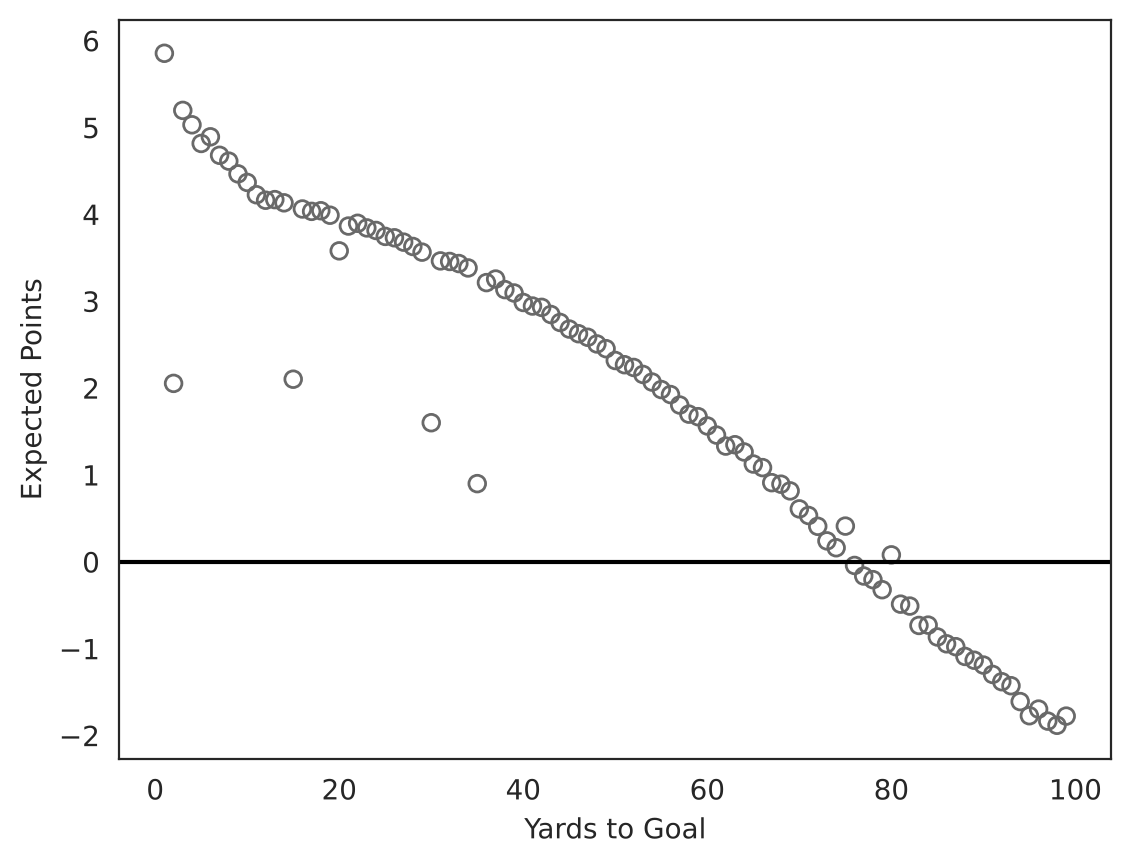

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking plotting style
sns.set_style('white')

# one dot per yard line
plt.scatter(ep_mean.index, ep_mean, facecolors='none', color='dimgray')
# horizontal line at 0: below it, the other team is more likely to score
plt.axhline(0, color='k')
plt.xlabel('Yards to Goal')
plt.ylabel('Expected Points')
plt.show()

## 8.2.6 Equilibrium Strategies in Python

In [5]:
# a function for determining the equilibrium strategies.
def q_fun(theta, Ep):
    """
    Equilibrium strategies of the Offense and of the Defense
    * theta has the four conditional probabilities of success,
      in this order: p_rr, p_rp, p_pr, p_pp
      (first letter for the Offense, second for the Defense, r is Run, p is Pass)
    * Ep is a matrix of expected points with three columns:
      successful run, successful pass and failure
    * returns the probability of playing Pass for the Offense (qo)
      and for the Defense (qd)
    """
    # python starts counting at 0, so the first column is Ep[:, 0]
    Ep_run = Ep[:, 0]
    Ep_pass = Ep[:, 1]
    Ep_fail = Ep[:, 2]

    # value for the Offense of each pair of actions
    V_rr = -(1 - theta[0])*Ep_fail + theta[0]*Ep_run
    V_rp = -(1 - theta[1])*Ep_fail + theta[1]*Ep_run
    V_pr = -(1 - theta[2])*Ep_fail + theta[2]*Ep_pass
    V_pp = -(1 - theta[3])*Ep_fail + theta[3]*Ep_pass

    # each team mixes so that the other team is indifferent between Run and Pass
    qo = (V_rp - V_rr)/((V_rp - V_rr) + (V_pr - V_pp))
    qd = (V_pr - V_rr)/((V_pr - V_rr) + (V_rp - V_pp))

    # forcing results to be probabilities.
    # numpy works on the whole vector, so we do not need the loop of the R code
    qo = np.minimum(np.maximum(qo, 0), 1)
    qd = np.minimum(np.maximum(qd, 0), 1)

    # a dictionary in place of the list of R: q['qo'] in Python is q$qo in R
    return {'qo': qo, 'qd': qd}

## 8.2.7 Simulation of Third and Fourth Down Game

In [6]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

N = 2000 # number of plays

# parameters of the model
# conditional probabilities
theta = np.array([0.2, 0.8, 0.5, 0.1])

# current yards to go.
Y = 50 + 20*np.random.rand(N)

# yards to go after punt.
# loc is the mean, and the standard deviation is 1 when we do not give it
Yk = Y - np.random.normal(loc=35, size=N)
# np.where does the job of ifelse in R
Yk = np.where(Yk > 0, Yk, 20)

# yards to go after pass
Yp = Y - np.random.normal(loc=15, size=N)
Yp = np.where(Yp > 0, Yp, 0)

# yards to go after run
Yr = Y - np.random.normal(loc=3, size=N)
Yr = np.where(Yr > 0, Yr, 0)

# an expected points function to approximate figure above.
def EP(x):
    return 5 - 5*x/100

# equilibrium strategies
# third down: after a failure the team punts,
# and the other team starts where the punt lands
q3 = q_fun(theta, np.c_[EP(Yr), EP(Yp), EP(100 - Yk)])
# fourth down: after a failure the other team starts at the same spot
q4 = q_fun(theta, np.c_[EP(Yr), EP(Yp), EP(100 - Y)])

In [7]:
# probability of playing Pass for the Offense (O) and for the Defense (D),
# on third down and on fourth down
tab_q = pd.DataFrame({'3rd O Pass': q3['qo'],
                      '3rd D Pass': q3['qd'],
                      '4th O Pass': q4['qo'],
                      '4th D Pass': q4['qd']})
tab_q.describe()

,3rd O Pass,3rd D Pass,4th O Pass,4th D Pass
count,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.560301,0.362857,0.573204,0.342427
std,0.004854,0.007685,0.003211,0.005085
min,0.542647,0.338534,0.561650,0.326100
25%,0.556990,0.357841,0.571003,0.338990
50%,0.560407,0.362689,0.573284,0.342300
75%,0.563469,0.368098,0.575375,0.345912
max,0.575663,0.390809,0.583516,0.360721


In [8]:
# third down
# the Offense plays Pass with probability qo
Pass = np.random.rand(N) < q3['qo']

# the probability of success depends on the play of the Offense
# and on the mix of the Defense
# ~Pass means "not Pass" (!Pass in R)
success3 = np.random.rand(N) < (Pass*(theta[2]*(1 - q3['qd']) + theta[3]*q3['qd']) +
                                (~Pass)*(theta[0]*(1 - q3['qd']) + theta[1]*q3['qd']))

# this is created to simulate the estimator below.
play = np.where(Pass, "pass", "run")

# fourth down
Pass = np.random.rand(N) < q4['qo']
success4 = np.random.rand(N) < (Pass*(theta[2]*(1 - q4['qd']) + theta[3]*q4['qd']) +
                                (~Pass)*(theta[0]*(1 - q4['qd']) + theta[1]*q4['qd']))

In [9]:
# success rate on third down
print(np.mean(success3))

0.4035


In [10]:
# success rate on fourth down
print(np.mean(success4))

0.3905


## 8.3.2 Simulated Moments OLS

In [11]:
# the data of chapter 1, but the standard deviation of u is 2 and not 1
np.random.seed(123456789)

N = 500
a = 2
b = 3
x = np.random.rand(N)
# scale is the standard deviation (sd in R)
u = np.random.normal(loc=0, scale=2, size=N)
y = a + b*x + u

In [12]:
def f_1mom(beta, y, X):
    """
    First moment estimator
    * beta has the intercept and the slope
    * returns the mean of the squared unobserved term
    """
    # adds a column of 1's for the intercept
    X = np.c_[np.ones(len(y)), X]
    sos = np.mean((y - X.dot(beta))**2)
    return sos

def f_2mom(par, y, X):
    """
    Second moment estimator
    * par has log(sigma) first, then the intercept and the slope
    * returns the square of the mean of
      (squared unobserved term minus sigma squared)
    """
    X = np.c_[np.ones(len(y)), X]
    sigma = np.exp(par[0])  # use to keep positive
    # all the parameters but the first one (par[-1] in R)
    beta = par[1:]
    sos = np.mean((y - X.dot(beta))**2 - sigma**2)**2
    return sos

In [13]:
from scipy.optimize import minimize

# optim() in R uses the Nelder-Mead method when we do not give a method,
# so we ask minimize() for the same method
# x0 has the start values (par in R)
# args has the other inputs of the function, here y and X
a = minimize(f_1mom, x0=[2, 3], args=(y, x), method='Nelder-Mead')

# beta
# the estimates are in .x (in $par in R)
a.x

array([2.03653293, 2.96546301])

In [14]:
b = minimize(f_2mom, x0=[np.log(2), 2, 3], args=(y, x), method='Nelder-Mead')

# sigma
print(np.exp(b.x[0]))

1.9566679912295077


In [15]:
# beta
# one moment for three parameters: many values of beta give a moment of zero,
# and the search stops at one of them, not far from the start values
b.x[1:]

array([2.06441732, 3.12124078])

In [16]:
def f_gmm_simple(par, y, X):
    """
    Sum of the first and of the second moment estimators,
    with the same weight for the two
    """
    X = np.c_[np.ones(len(y)), X]
    sigma = np.exp(par[0])
    beta = par[1:]
    sos = (np.mean((y - X.dot(beta))**2) +
           np.mean(((y - X.dot(beta))**2 - sigma**2)**2))
    return sos

c = minimize(f_gmm_simple, x0=[np.log(2), 2, 3], args=(y, x), method='Nelder-Mead')

# sigma
print(np.exp(c.x[0]))

1.9649840047287843


In [17]:
# beta
c.x[1:]

array([1.92942125, 3.49677997])

## 8.3.4 GMM OLS Estimator in Python

In [18]:
# in python the inverse matrix can be found using
# the inv() function (from Numpy)
from numpy.linalg import inv

def f_gmm(G, K):
    """
    General GMM function
    * G is a matrix with one row per moment and one column per observation
    * K is the number of moments
    * returns g'Wg, where g has the mean of each moment
      and W is the weighting matrix
    """
    # number of observations (the columns of G)
    N = G.shape[1]
    if K == G.shape[0]:
        # a check that the matrix G has K rows
        # mean of each row, missing values left out (rowMeans with na.rm in R)
        g = np.nanmean(G, axis=1)
        try:
            # try lets the function work even if there is an error
            # weighting matrix: the inverse of G times its transpose, over N
            W = inv(G.dot(G.T)/N)
            # if there is no error, W is a matrix.
            return g.dot(W).dot(g)
        except np.linalg.LinAlgError:
            # inv() gives this error when the matrix has no inverse
            # allow estimation assuming W is identity matrix
            return g.dot(g)
    else:
        return "ERROR: incorrect dimension"

def f_ols_gmm(par, y, X):
    """
    GMM estimator of OLS, with the first and the second moment
    of the unobserved term
    """
    X = np.c_[np.ones(len(y)), X]
    sigma = np.exp(par[0])
    beta = par[1:]
    # first moment: the mean of the unobserved term is 0
    g1 = y - X.dot(beta)
    # second moment: the mean of its square is sigma squared
    g2 = (y - X.dot(beta))**2 - sigma**2
    # np.c_ puts g1 and g2 in two columns, and .T turns them into two rows
    return f_gmm(np.c_[g1, g2].T, K=2)

In [19]:
d = minimize(f_ols_gmm, x0=[np.log(2), 2, 3], args=(y, x), method='Nelder-Mead')

# sigma
print(np.exp(d.x[0]))

1.9537862580512153


In [20]:
# beta
d.x[1:]

array([1.97107189, 3.09972023])

## 8.3.5 GMM of Returns to Schooling

In [21]:
# the data and the cleaning are the ones of chapter 3
x = pd.read_csv('../data/nls.csv')

In [22]:
# we take the cleaning functions of chapter 2

def convert_col_to_numeric(df, col):
    # values which are not numbers (here ".") become NAs
    df[col] = pd.to_numeric(df[col], errors = 'coerce')
    return df

def remove_missing(df, col):
    condition = df[col].isna() == False
    return df[condition]

def get_working_years_after_school(df):
    """
    We create new variables:
    * exp: working years after school
    * exp2: experience squared divided by 100
    """
    df['exp'] = df['age76']-df['ed76']-6
    df['exp2'] = df['exp']**2/100
    return df

In [23]:
# and we perform the data cleaning using the .pipe operator
# on the original dataset x

x1 = (
    x
    .pipe(convert_col_to_numeric, col = 'lwage76')
    .pipe(remove_missing, col = 'lwage76')
    .pipe(get_working_years_after_school)
)

In [24]:
# we use numpy arrays (and not pandas dataframes) for the matrix algebra
y = np.array(x1['lwage76'])
X = np.array(x1[['ed76', 'exp', 'exp2', 'black', 'reg76r',
                 'smsa76r', 'smsa66r', 'reg662', 'reg663',
                 'reg664', 'reg665', 'reg666', 'reg667',
                 'reg668', 'reg669']])

# age squared, as in chapter 3
# (it is in the R code of the book but it is not used in this section)
x1['age2'] = x1['age76']**2

In [25]:
def f_iv_gmm(beta, y, X, Z):
    """
    GMM estimator with two instruments
    * Z is the matrix of instruments of schooling, one column per instrument
    * each moment is an instrument times the unobserved term
    """
    X = np.c_[np.ones(len(y)), X]
    g1 = Z[:, 0]*(y - X.dot(beta))
    g2 = Z[:, 1]*(y - X.dot(beta))
    return f_gmm(np.c_[g1, g2].T, K=2)

In [26]:
# OLS estimator, as in chapters 2 and 3
X1 = np.c_[np.ones(len(y)), X]
beta = inv(X1.T.dot(X1)).dot(X1.T).dot(y)

# position 0 is the intercept, position 1 is ed76 (beta[2] in R)
print(beta[1])

0.07469325940205074


In [27]:
# the two instruments for education:
# distance to a 4 year college and both parents at home at age 14
Z = np.array(x1[['nearc4', 'momdad14']])

# GMM estimator, the OLS estimates are the start values
a = minimize(f_iv_gmm, x0=beta, args=(y, X, Z), method='Nelder-Mead')
print(a.x[1])

0.07497321329208295


The book has 0.0735, a bit below the OLS estimate, and here the search stops at 0.0750, a bit above. There are two moments for sixteen parameters, so many values of beta set the two moments to zero. The result depends on the first steps of the search, which are not the same in `optim` of R and in `minimize` of scipy.

In [28]:
# value of the GMM function at the OLS estimates and at the GMM estimates
# a.fun is the value at the minimum (a$value in R), it is about zero
print(f_iv_gmm(beta, y, X, Z))
print(a.fun)

0.00019798974929926462
3.444561161101781e-10


## 8.4.2 Third Down GMM Estimator in Python

In [29]:
# the GMM estimator, which calls the general GMM function above.
def p3_fun(par, Ep, s, play):
    """
    GMM estimator of the third down game
    * par has the four parameters, on the whole real line
    * Ep is the matrix of expected points (run, pass, failure)
    * s is 1 for a success and 0 for a failure
    * play is "pass" or "run"
    """
    # using sigmoid function to keep values between 0 and 1
    theta = np.exp(par)/(1 + np.exp(par))

    # determine the equilibrium strategies.
    q3 = q_fun(theta, Ep)

    # moments
    Pass = play == "pass"
    # success rate after a pass
    g1 = Pass*(s - theta[2]*(1 - q3['qd']) - theta[3]*q3['qd'])
    # success rate after a run
    g2 = (~Pass)*(s - theta[0]*(1 - q3['qd']) - theta[1]*q3['qd'])
    # probability that the Offense plays Pass
    g3 = Pass - q3['qo']

    # note the transpose.
    G = np.c_[g1, g2, g3].T
    return f_gmm(G, 3)

In [30]:
# we take the plays simulated in section 8.2.7
EP1 = np.c_[EP(Yr), EP(Yp), EP(100 - Yk)]

# maxiter is the maximum number of iterations (maxit in R)
a1 = minimize(p3_fun, x0=np.log(2*theta), args=(EP1, success3, play),
              method='Nelder-Mead', options={'maxiter': 10000})

# back to probabilities
# the true values are 0.2, 0.8, 0.5 and 0.1
np.exp(a1.x)/(1 + np.exp(a1.x))

array([0.25197911, 0.62927943, 0.50005415, 0.24821643])

## 8.5.1 NFL Data

In [31]:
# the first column of the file has no name, it holds the row names of R
# pandas calls it 'Unnamed: 0' and we do not use it
x = pd.read_csv('../data/NFLQ1.csv')
x.head()

,Unnamed: 0,play_id,game_id,home_team,away_team,posteam,defteam,yardline_100,game_date,down,goal_to_go,ydstogo,play_type,pass_length,run_location,run_gap,field_goal_result,ep,epa
0,1,46,2009091000,PIT,TEN,PIT,TEN,30.0,2009-09-10,NaN,0.0,0,kickoff,NaN,NaN,NaN,NaN,0.323526,2.014474
1,2,68,2009091000,PIT,TEN,PIT,TEN,58.0,2009-09-10,1.0,0.0,10,pass,short,NaN,NaN,NaN,2.338000,0.077907
2,3,92,2009091000,PIT,TEN,PIT,TEN,53.0,2009-09-10,2.0,0.0,5,run,NaN,right,end,NaN,2.415907,-1.402760
3,4,113,2009091000,PIT,TEN,PIT,TEN,56.0,2009-09-10,3.0,0.0,8,pass,deep,NaN,NaN,NaN,1.013147,-1.712583
4,5,139,2009091000,PIT,TEN,PIT,TEN,56.0,2009-09-10,4.0,0.0,8,punt,NaN,NaN,NaN,NaN,-0.699436,2.097796


In [32]:
# We define a bunch of functions to prepare the data
# in an organised fashion

def add_id(df):
    # row number, starting at 1 as in R
    df['id'] = df.index + 1
    return df

def add_next_play(df):
    """
    The next play listed in the data gives the "result" of the play:
    * res_pos: team which has the ball in the next play
    * res_ep: expected points in the next play
    * res_game: game of the next play
    * res_down: down of the next play
    """
    # .shift(-1) moves a column one row up: each row gets the value of the next row
    # and the last row gets a missing value
    df['res_pos'] = df['posteam'].shift(-1)
    df['res_ep'] = df['ep'].shift(-1)
    df['res_game'] = df['game_id'].shift(-1)
    df['res_down'] = df['down'].shift(-1)
    return df

def add_diff_ep(df):
    """
    diff_ep: change in expected points between the play and the next play
    """
    # the expected points are the ones of the team which has the ball
    # if the ball goes to the other team, we take the negative
    # in R a comparison with a missing value gives a missing value,
    # in Python it gives False
    # (the regressions below are the same with one or the other)
    df['res_ep'] = np.where(df['posteam']==df['res_pos'], df['res_ep'], -df['res_ep'])
    df['diff_ep'] = df['res_ep'] - df['ep']
    # missing value if the next play is in another game
    df['diff_ep'] = np.where(df['game_id']==df['res_game'], df['diff_ep'], np.nan)
    return df

def add_year(df):
    # this uses "regular expressions".
    # it subs out everything after the "-".
    df['year'] = df['game_date'].str.replace("-.*", "", regex=True)
    # the year is still text, we convert it to a number
    df['year'] = pd.to_numeric(df['year'])
    return df

def add_succ(df):
    """
    succ: success of the play
    * 1 if a third down is followed by a first down of the same team
    * 0 if the next play is a fourth down
    * missing in the other cases
    """
    df['succ'] = np.nan
    condition = (df['res_down']==1) & (df['posteam']==df['res_pos']) & (df['down']==3)
    df['succ'] = np.where(condition, 1, df['succ'])
    df['succ'] = np.where(df['res_down']==4, 0, df['succ'])
    return df

def add_pct_field(df):
    # yards to the goal line, as a share of the field
    df['pct_field'] = df['yardline_100']/100
    return df

In [33]:
# and we apply them using the .pipe operator
x = (
    x
    .pipe(add_id)
    .pipe(add_next_play)
    .pipe(add_diff_ep)
    .pipe(add_year)
    .pipe(add_succ)
    .pipe(add_pct_field)
)

## 8.5.2 Estimating Third Down Game in Python

In [34]:
# using statsmodels for the regressions, as in chapters 2 and 3
import statsmodels.formula.api as sm
from statsmodels.iolib.summary2 import summary_col

# change in expected points after a third down run which gets a first down
lm_run = sm.ols(formula="diff_ep ~ ydstogo + pct_field + year",
                data=x[(x['play_type']=="run") & (x['down']==3) & (x['succ']==1)]).fit()

# same for a third down pass
lm_pass = sm.ols(formula="diff_ep ~ ydstogo + pct_field + year",
                 data=x[(x['play_type']=="pass") & (x['down']==3) & (x['succ']==1)]).fit()

# change in expected points after a punt
lm_punt = sm.ols(formula="diff_ep ~ ydstogo + pct_field + year",
                 data=x[x['play_type']=="punt"]).fit()

In [35]:
# (1) is the run, (2) is the pass and (3) is the punt
print(summary_col([lm_run,lm_pass,lm_punt],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)'],
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'R2':lambda x: "{:.3f}".format(x.rsquared)}
            ))


                 (1)      (2)       (3)    
-------------------------------------------
Intercept      -8.146   10.331   -63.722***
               (10.095) (7.675)  (10.314)  
ydstogo        0.220*** 0.153*** 0.019***  
               (0.005)  (0.003)  (0.003)   
pct_field      0.493*** 1.808*** 1.874***  
               (0.069)  (0.053)  (0.102)   
year           0.004    -0.005   0.031***  
               (0.005)  (0.004)  (0.005)   
R-squared      0.604    0.503    0.076     
R-squared Adj. 0.603    0.503    0.075     
N              1411     3896     5860      
R2             0.604    0.503    0.076     
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


In [36]:
# predicted expected points for a run, a pass and a punt
# these are calculated for every play in the data
X = np.c_[np.ones(len(x)), x['ydstogo'], x['pct_field'], x['year']]

# .params has the coefficients of the regression
x['pass_ep'] = x['ep'] + X.dot(np.array(lm_pass.params))
x['run_ep'] = x['ep'] + X.dot(np.array(lm_run.params))
x['punt_ep'] = x['ep'] + X.dot(np.array(lm_punt.params))

In [37]:
# one row for each to go distance (4) and each yard line (30),
# one column for each of the four parameters
theta_hat = np.zeros((4*30, 4))

k = 0 # python starts counting at 0
for i in range(1, 5):
    tg = i # to go distance.
    for j in range(1, 31):
        yl = 29 + j # yardline

        # create subset for analysis
        # third downs, 10 yards either side of the position,
        # 1 yard either side of the to go distance, pass or run
        index = ((x['down']==3) &
                 (x['yardline_100'] > yl) & (x['yardline_100'] < (yl+20)) &
                 (x['ydstogo'] > tg - 2) & (x['ydstogo'] < tg + 2) &
                 ((x['play_type']=="pass") | (x['play_type']=="run")))
        y = x[index]

        # we remove the rows with a missing value in one of these columns
        y_na = y.dropna(subset=['run_ep', 'pass_ep', 'punt_ep', 'succ'])

        # GMM to determine parameters (conditional probabilities)
        # the start values are four random numbers, as in the book,
        # and the estimates depend on them
        a1 = minimize(p3_fun,
                      x0=np.random.normal(loc=0, scale=2, size=4),
                      args=(np.array(y_na[['run_ep', 'pass_ep', 'punt_ep']]),
                            np.array(y_na['succ']),
                            np.array(y_na['play_type'])),
                      method='Nelder-Mead',
                      options={'maxiter': 10000})
        theta_hat[k, :] = np.exp(a1.x)/(1 + np.exp(a1.x))
        k = k + 1

## 8.5.3 Predicting the Fourth Down Game

In [38]:
# expected points on first down, by distance to the goal line
# I() lets us write the square inside the formula (** is ^ in R)
lm_over = sm.ols(formula="ep ~ pct_field + I(pct_field**2)",
                 data=x[x['down']==1]).fit()

# expected points after a turnover on downs:
# the other team has a first down at the same spot, so with 1 - pct_field to go
# and we take the negative because the points are for the other team
X_over = np.c_[np.ones(len(x)), 1 - x['pct_field'], (1 - x['pct_field'])**2]
x['over_ep'] = -X_over.dot(np.array(lm_over.params))

In [39]:
def p4_fun(theta, Ep):
    """
    Fourth down game
    * theta has the four conditional probabilities
    * Ep is the matrix of expected points (run, pass, failure)
    * returns the probability of success (p4)
      and the expected points of going for it (Epgfi)
    """
    q4 = q_fun(theta, Ep)
    # probability of a successful pass and of a successful run
    p4p = q4['qo']*(theta[2]*(1 - q4['qd']) + theta[3]*q4['qd'])
    p4r = (1 - q4['qo'])*(theta[0]*(1 - q4['qd']) + theta[1]*q4['qd'])
    p4 = p4r + p4p
    # expected points going for it.
    Epgfi = p4r*Ep[:, 0] + p4p*Ep[:, 1] + (1 - p4)*Ep[:, 2]
    return {'p4': p4, 'Epgfi': Epgfi}

In [40]:
# one row for each to go distance, one column for each yard line
tab_res = np.zeros((4, 30))
prob_actual = np.zeros((4, 30))
prob_pred = np.zeros((4, 30))

k = 0
for i in range(1, 5):
    tg = i # to go distance.
    for j in range(1, 31):
        yl = 29 + j # yardline

        # create subset for analysis
        index3 = ((x['down']==3) &
                  (x['yardline_100'] > yl) & (x['yardline_100'] < (yl+20)) &
                  (x['ydstogo'] > tg - 2) & (x['ydstogo'] < tg + 2) &
                  ((x['play_type']=="pass") | (x['play_type']=="run")))
        y = x[index3]

        # determine predicted success on 4th down.
        succ4 = p4_fun(theta_hat[k, :],
                       np.array(y[['run_ep', 'pass_ep', 'over_ep']]))

        # Actual frequency of going for it on 4th down.
        index4 = ((x['down']==4) &
                  (x['yardline_100'] > yl) & (x['yardline_100'] < (yl+20)) &
                  (x['ydstogo'] > tg - 2) & (x['ydstogo'] < tg + 2))
        z = x[index4]
        # go is 1 for a run or a pass, 0 for a punt
        # and missing for the other plays
        go = np.where((z['play_type']=="run") | (z['play_type']=="pass"), 1, np.nan)
        go = np.where(z['play_type']=="punt", 0, go)

        # expected points of punting minus expected points of going for it
        # we remove the missing values (na.rm = TRUE in R)
        diff = np.array(y['punt_ep']) - succ4['Epgfi']
        diff = diff[np.isnan(diff)==False]

        # i and j start at 1, the rows and columns of python start at 0
        # relative value of punting
        tab_res[i-1, j-1] = np.mean(diff)
        # predicted probability of going for it
        prob_pred[i-1, j-1] = np.mean(diff < 0)
        # actual probability of going for it.
        # np.nanmean takes the mean without the missing values
        prob_actual[i-1, j-1] = np.nanmean(go)
        k = k + 1

In [41]:
# expected points from punting over going for it,
# one column for each to go distance, summary over the 30 yard lines
# .T to have the to go distances in columns
tab_punt = pd.DataFrame(tab_res.T,
                        columns=['1 To Go', '2 To Go', '3 To Go', '4 To Go'])
tab_punt.describe()

,1 To Go,2 To Go,3 To Go,4 To Go
count,30.000000,30.000000,30.000000,30.000000
mean,0.947643,1.348118,1.544934,1.951044
std,0.832488,0.972566,0.805513,1.011292
min,0.134287,0.165231,0.908196,-0.591673
25%,0.444558,0.896149,1.166625,1.569923
50%,0.810523,1.145401,1.306557,1.649217
75%,1.053651,1.618999,1.546314,1.863897
max,4.393070,4.480426,4.385257,4.612021


## 8.5.4 Testing Rationality of NFL Coaches

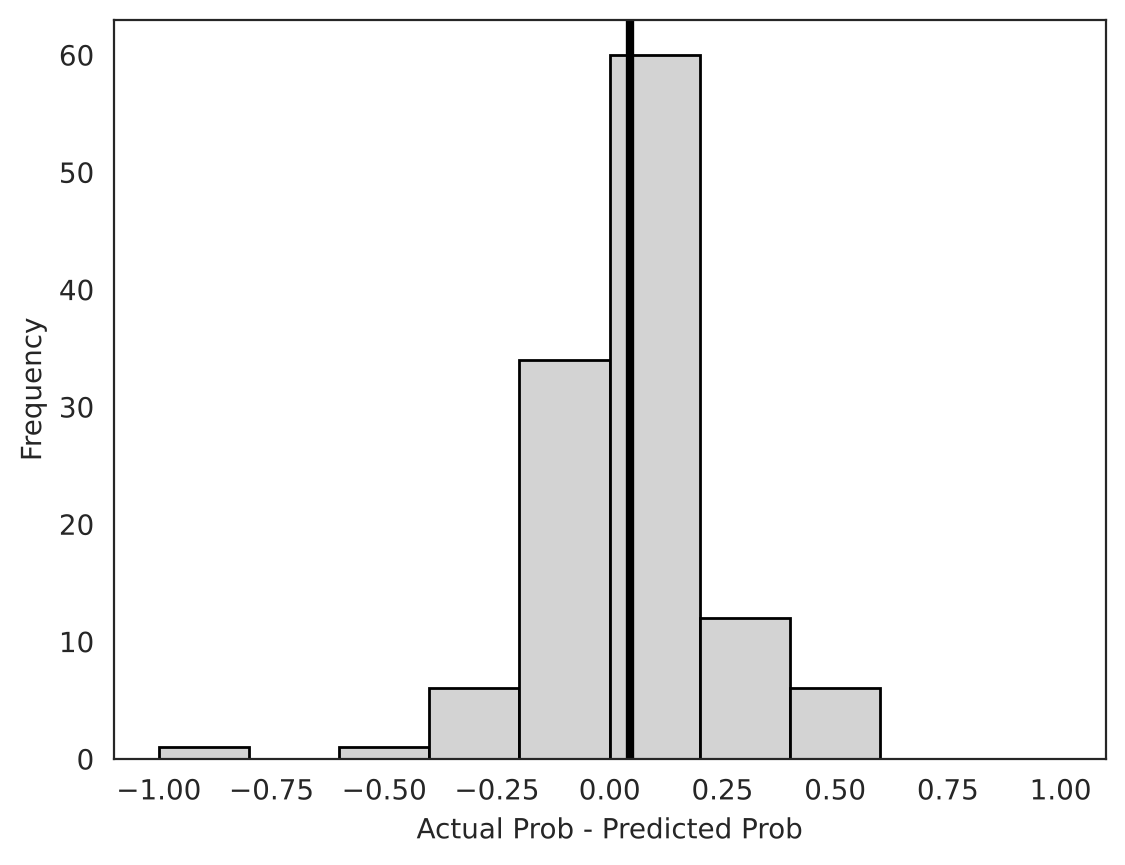

In [42]:
# difference between the actual and the predicted probability of going for it
# .flatten() puts the 4 x 30 values in one vector
diff_prob = (prob_actual - prob_pred).flatten()

# 10 bars of width 0.2, between -1 and 1
plt.hist(diff_prob, bins=np.linspace(-1, 1, 11), color='lightgrey', edgecolor='k')
# vertical line at the mean of the differences
plt.axvline(np.mean(diff_prob), color='k', linewidth=3)
plt.xlabel('Actual Prob - Predicted Prob')
plt.ylabel('Frequency')
plt.show()

In [43]:
# mean of the differences
print(np.mean(diff_prob))

0.045775650728864054
